# 03 — Models and cross-validation (2024)

**Question:** how well can we tell rice parcels from other parcels, and is machine learning even needed, or does a
simple rule from the physics do just as well?

**Models, from simplest to most flexible:**
0. **Majority class**: always "not rice". A sanity floor that shows why accuracy is the wrong metric here.
1. **Physics rule**: rice if the parcel got dark during flooding *and* brightened afterwards
   (`vh_flood_min < T` and `vh_rise > R`). The thresholds T and R are learned from the training folds only.
2. **Logistic regression** on the six physics features (after standardising them).
3. **LightGBM** (gradient-boosted decision trees) on the physics features plus the whole 12-day time grid.
   Fixed, sensible settings and no tuning loop, so the cross-validation scores stay honest.

**Cross-validation (CV):** the data is cut into 5 parts (*folds*). Each model is trained on 4 and tested on the
5th, five times, so every parcel is predicted exactly once by a model that never saw it (*out-of-fold* predictions).
We do this twice:
- **spatial CV**: folds made of whole 5 km blocks (notebook 02), the honest estimate for new places;
- **random CV**: parcels assigned at random, which mixes neighbours into training and testing. The difference to
  spatial CV shows how much leakage between neighbours would inflate the scores.

**Model choice rule, fixed before looking at the results:** take the *simplest* model whose spatial-CV F1 is within
one standard deviation of the best model's F1. That model is retrained on all of 2024 and frozen for the 2025 test.

In [1]:
import json
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))
plt.rcParams["figure.dpi"] = 72  # keeps the saved notebook small

from ricesar.config import DATA_DIR, load_config
from ricesar.download import patches_with_parcels
from ricesar.labels import load_labels, project
from ricesar.models import PhysicsRule, cross_validate, grid_features, make_ablation_models, make_models, summarize

config = load_config(PROJECT_ROOT / "configs" / "camargue.toml")
YEAR = 2024
data = pd.read_csv(DATA_DIR / "processed" / f"dataset_{config['name']}_{YEAR}.csv", index_col="pid")
y = data["is_rice"].astype(bool)
models = make_models(grid_features(data))
print(f"{len(data)} parcels, {y.sum()} rice ({y.mean():.1%}), {data['block'].nunique()} spatial blocks")

13613 parcels, 1524 rice (11.2%), 98 spatial blocks


## 1. Cross-validation: spatial vs random folds

In [2]:
spatial_folds = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0).split(data, y, groups=data["block"]))
random_folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=0).split(data, y))

for name, folds in [("spatial", spatial_folds), ("random", random_folds)]:
    rice_share = [f"{y.iloc[test].mean():.1%}" for _, test in folds]
    print(f"{name:8s} test-fold sizes {[len(test) for _, test in folds]}, rice share {rice_share}")

spatial_scores, spatial_oof = cross_validate(models, data, spatial_folds)
random_scores, random_oof = cross_validate(models, data, random_folds)

spatial  test-fold sizes [3082, 2040, 2020, 3776, 2695], rice share ['12.6%', '11.0%', '3.3%', '14.0%', '11.7%']
random   test-fold sizes [2723, 2723, 2723, 2722, 2722], rice share ['11.2%', '11.2%', '11.2%', '11.2%', '11.2%']


In [3]:
spatial_summary = summarize(spatial_scores)
print("SPATIAL cross-validation (mean and std over 5 folds)")
spatial_summary

SPATIAL cross-validation (mean and std over 5 folds)


accuracy        precision        recall            f1  \
                        mean    std      mean    std   mean    std   mean   
model                                                                       
majority               0.895  0.042     0.000  0.000  0.000  0.000  0.000   
physics rule           0.950  0.015     0.739  0.080  0.764  0.043  0.750   
logistic regression    0.959  0.011     0.831  0.108  0.708  0.072  0.764   
lightgbm               0.993  0.005     0.975  0.018  0.960  0.025  0.967   

                           pr_auc         
                       std   mean    std  
model                                     
majority             0.000  0.105  0.042  
physics rule         0.058  0.791  0.093  
logistic regression  0.087  0.823  0.080  
lightgbm             0.013  0.994  0.004

In [4]:
print("RANDOM cross-validation (mean and std over 5 folds)")
summarize(random_scores)

RANDOM cross-validation (mean and std over 5 folds)

accuracy        precision        recall            f1  \
                        mean    std      mean    std   mean    std   mean   
model                                                                       
majority               0.888  0.000     0.000  0.000  0.000  0.000  0.000   
physics rule           0.947  0.003     0.762  0.014  0.772  0.013  0.767   
logistic regression    0.957  0.002     0.863  0.014  0.730  0.014  0.791   
lightgbm               0.995  0.000     0.981  0.006  0.972  0.006  0.977   

                           pr_auc         
                       std   mean    std  
model                                     
majority             0.000  0.112  0.000  
physics rule         0.012  0.816  0.021  
logistic regression  0.011  0.845  0.015  
lightgbm             0.002  0.994  0.004

**Reading the tables:** "majority" has high accuracy but zero precision/recall/F1: it never finds rice. That's
the accuracy trap. For the other models, compare F1 and PR-AUC. The *std* (standard deviation over folds) shows
how much the score depends on which blocks ended up in the test fold; differences smaller than the std are not
convincing.

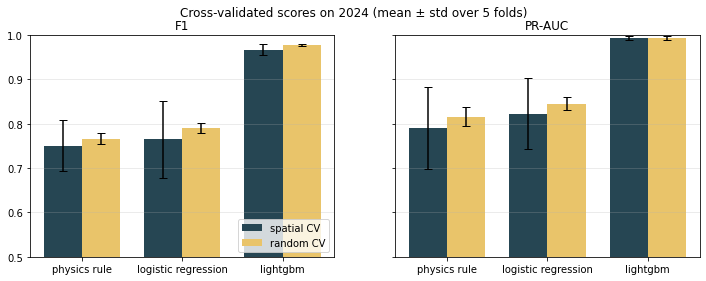

F1 random minus spatial (leakage effect): {'physics rule': 0.016, 'logistic regression': 0.026, 'lightgbm': 0.01}


In [5]:
metrics = ["f1", "pr_auc"]
model_names = [name for name in models if name != "majority"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, metric in zip(axes, metrics):
    x = np.arange(len(model_names))
    for offset, (label, table, color) in enumerate(
        [("spatial CV", spatial_scores, "#264653"), ("random CV", random_scores, "#e9c46a")]
    ):
        stats = table.groupby("model")[metric].agg(["mean", "std"]).loc[model_names]
        ax.bar(x + (offset - 0.5) * 0.38, stats["mean"], 0.38, yerr=stats["std"], capsize=4, color=color, label=label)
    ax.set_xticks(x)
    ax.set_xticklabels(model_names)
    ax.set_title(metric.upper().replace("_", "-"))
    ax.set_ylim(0.5, 1.0)
    ax.grid(axis="y", alpha=0.3)
axes[0].legend(loc="lower right")
fig.suptitle("Cross-validated scores on 2024 (mean ± std over 5 folds)")
fig.savefig(PROJECT_ROOT / "reports" / "figures" / "03_cv_scores.png", dpi=90, bbox_inches="tight")
plt.show()

gap = (random_scores.groupby("model")["f1"].mean() - spatial_scores.groupby("model")["f1"].mean()).loc[model_names]
print("F1 random minus spatial (leakage effect):", gap.round(3).to_dict())

## 2. What did the physics rule learn?

The rule's two thresholds are fitted on each training fold. If they are similar across folds, the rule is stable;
compare them with the −24 dB we read off the histogram in notebook 01.

In [6]:
rows = []
for fold, (train, _) in enumerate(spatial_folds):
    rule = PhysicsRule().fit(data.iloc[train], y.iloc[train])
    rows.append({"fold": fold, "flood VH below (dB)": rule.threshold_db_, "rise above (dB)": rule.rise_db_})
pd.DataFrame(rows).set_index("fold")

,flood VH below (dB),rise above (dB)
fold,,
0,-23.50,8.5
1,-23.50,8.5
2,-23.50,8.5
3,-23.25,8.5
4,-23.50,8.5


## 3. Choosing the model (rule fixed in advance)

In [7]:
f1_stats = spatial_scores.groupby("model", sort=False)["f1"].agg(["mean", "std"])
best = f1_stats["mean"].idxmax()
cutoff = f1_stats.loc[best, "mean"] - f1_stats.loc[best, "std"]
chosen = next(name for name in model_names if f1_stats.loc[name, "mean"] >= cutoff)  # simplest first
print(f"best spatial-CV F1: {best} ({f1_stats.loc[best, 'mean']:.3f} ± {f1_stats.loc[best, 'std']:.3f})")
print(f"simplest model within one std (F1 ≥ {cutoff:.3f}): {chosen}")

best spatial-CV F1: lightgbm (0.967 ± 0.013)
simplest model within one std (F1 ≥ 0.954): lightgbm


## 4. Ablation: is it the model or the inputs?

The comparison above changes **two things at once**: logistic regression got the 6 physics features, LightGBM got
those plus the whole 12-day time series. To see which change matters, we fill in the two missing combinations
(an *ablation*: change one thing at a time) and compare all four with the same spatial folds.

This is analysis only. The model choice in section 3 was fixed in advance among the original candidates and is not
changed by these extra variants.

In [8]:
ablation_scores, _ = cross_validate(make_ablation_models(grid_features(data)), data, spatial_folds)
all_scores = pd.concat([spatial_scores, ablation_scores])
f1 = all_scores.groupby("model")["f1"].agg(["mean", "std"])

def cell(name):
    return f"{f1.loc[name, 'mean']:.3f} ± {f1.loc[name, 'std']:.3f}"

grid_table = pd.DataFrame(
    {
        "6 physics features": [cell("logistic regression"), cell("lightgbm, 6 features only")],
        "+ full time series": [cell("logistic regression + series"), cell("lightgbm")],
    },
    index=["logistic regression (linear)", "LightGBM (trees)"],
)
summarize(ablation_scores).to_csv(PROJECT_ROOT / "reports" / "ablation_results.csv")
print("Spatial-CV F1 (mean ± std over 5 folds)")
grid_table

Spatial-CV F1 (mean ± std over 5 folds)


,6 physics features,+ full time series
logistic regression (linear),0.764 ± 0.087,0.938 ± 0.013
LightGBM (trees),0.788 ± 0.094,0.967 ± 0.013


**Reading it:** going *right* (adding the time series) changes the score much more than going *down* (a more
flexible model). Most of the gain comes from the **inputs**: the shape and timing of the whole season. The tree model
adds a smaller but consistent improvement on top. With the series, the linear model is still outside one std of LightGBM,
so it wouldn't have been chosen even as a candidate.

## 5. Error analysis (spatial CV, out-of-fold predictions)

Every parcel was predicted by a model that didn't see it in training. Where are the mistakes?

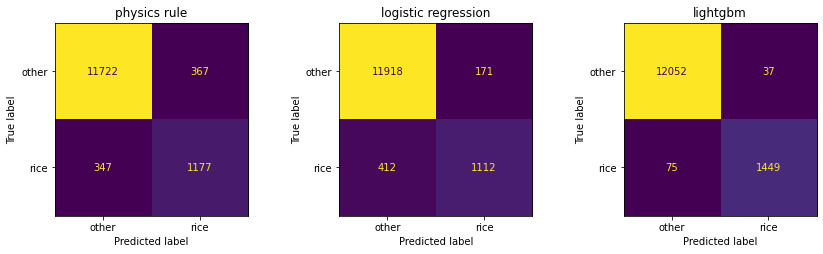

In [9]:
fig, axes = plt.subplots(1, len(model_names), figsize=(4 * len(model_names), 3.6))
for ax, name in zip(axes, model_names):
    ConfusionMatrixDisplay.from_predictions(
        y, spatial_oof[f"{name}_pred"].astype(bool), display_labels=["other", "rice"], ax=ax, colorbar=False
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()

In [10]:
analysis = data[["is_rice", "code_cultu", "group_name", "surf_parc"]].join(spatial_oof[[f"{chosen}_proba", f"{chosen}_pred"]])
analysis = analysis.rename(columns={f"{chosen}_proba": "proba", f"{chosen}_pred": "pred"})
analysis["pred"] = analysis["pred"].astype(bool)
false_alarms = analysis[analysis["pred"] & ~analysis["is_rice"]]
misses = analysis[~analysis["pred"] & analysis["is_rice"]]
print(f"{chosen}: {len(false_alarms)} false alarms, {len(misses)} missed rice parcels")
print("False alarms by declared crop code:", false_alarms["code_cultu"].value_counts().head(8).to_dict())

size_bins = pd.cut(analysis.loc[analysis["is_rice"], "surf_parc"], [0, 2, 5, 10, 1000],
                   labels=["< 2 ha", "2–5 ha", "5–10 ha", "> 10 ha"])
recall_by_size = analysis.loc[analysis["is_rice"], "pred"].groupby(size_bins, observed=False).agg(["mean", "size"])
recall_by_size.columns = ["recall", "rice parcels"]
recall_by_size.round(3)

lightgbm: 37 false alarms, 75 missed rice parcels
False alarms by declared crop code: {'MIS': 7, 'SOG': 6, 'BDH': 6, 'CAR': 3, 'TRN': 2, 'PTC': 2, 'CZH': 2, 'LUZ': 2}


,recall,rice parcels
surf_parc,,
< 2 ha,0.859,185
2–5 ha,0.958,593
5–10 ha,0.956,365
> 10 ha,0.979,381


**Possible label noise.** The parcels where the model is most confident *and* disagrees with the declared crop are
worth a look: some are model errors, some may be wrong or outdated declarations (e.g. a field declared as wheat that
was actually flooded rice). We can't tell from here without field checks, but this is how such a list would be
handed to an inspector.

In [11]:
analysis["disagreement"] = np.where(analysis["is_rice"], 1 - analysis["proba"], analysis["proba"])
analysis.sort_values("disagreement", ascending=False).head(20)[
    ["code_cultu", "group_name", "surf_parc", "is_rice", "proba"]
].round(3)

,code_cultu,group_name,surf_parc,is_rice,proba
pid,,,,,
20517,RIZ,rice,9.13,True,0.000
15140,JAC,fallow,2.66,False,1.000
19643,RIZ,rice,6.88,True,0.000
21231,RIZ,rice,12.06,True,0.000
16657,RIZ,rice,3.45,True,0.000
12255,RIZ,rice,1.63,True,0.000
18928,RIZ,rice,5.61,True,0.000
8821,RIZ,rice,0.87,True,0.000
22783,BDH,other cereals,56.99,False,1.000


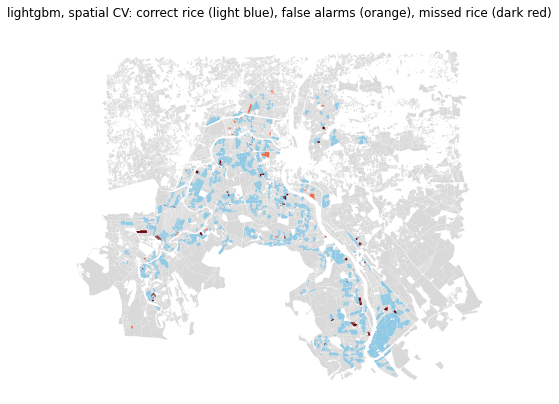

In [12]:
labels_utm = load_labels(config, YEAR)
labels_utm = project(labels_utm, patches_with_parcels(config, labels_utm)[0].crs.pyproj_crs()).set_index("pid")
outcome = pd.Series("correct", index=analysis.index)
outcome[analysis["pred"] & ~analysis["is_rice"]] = "false alarm"
outcome[~analysis["pred"] & analysis["is_rice"]] = "missed rice"
mapped = labels_utm.loc[analysis.index].assign(outcome=outcome)

fig, ax = plt.subplots(figsize=(8, 8))
mapped[mapped["outcome"] == "correct"].plot(ax=ax, color="#d9d9d9", linewidth=0)
mapped[(mapped["outcome"] == "correct") & analysis["is_rice"]].plot(ax=ax, color="#8ecae6", linewidth=0)
mapped[mapped["outcome"] == "false alarm"].plot(ax=ax, color="#e76f51", linewidth=0)
mapped[mapped["outcome"] == "missed rice"].plot(ax=ax, color="#6a040f", linewidth=0)
ax.set_title(f"{chosen}, spatial CV: correct rice (light blue), false alarms (orange), missed rice (dark red)")
ax.set_axis_off()
fig.savefig(PROJECT_ROOT / "reports" / "figures" / "03_error_map.png", dpi=90, bbox_inches="tight")
plt.show()

## 6. Freeze the chosen model

The chosen model is retrained on **all** 2024 parcels and saved, together with everything needed to apply it
unchanged to 2025: the feature columns, the track and the season windows. From now on it must not change.

In [13]:
estimator, columns = models[chosen]
final_model = clone(estimator).fit(data[columns], y)
out_dir = PROJECT_ROOT / "outputs"
out_dir.mkdir(exist_ok=True)
joblib.dump(final_model, out_dir / "model.joblib")
meta = {"model": chosen, "trained_on": YEAR, "features": columns, "track": config["s1"]["track"],
        "season": config["season"], "windows": config["features"]}
(out_dir / "model.json").write_text(json.dumps(meta, indent=2))

table = pd.concat({"spatial": summarize(spatial_scores), "random": summarize(random_scores)})
table.to_csv(PROJECT_ROOT / "reports" / "cv_results.csv")
print("saved outputs/model.joblib, outputs/model.json, reports/cv_results.csv")

saved outputs/model.joblib, outputs/model.json, reports/cv_results.csv


## Summary (2024, 13,613 parcels, 1,524 rice)

| model | spatial-CV F1 | precision | recall | PR-AUC |
|---|---|---|---|---|
| majority ("never rice") | 0.00 | 0.00 | 0.00 | 0.11 |
| physics rule (2 thresholds) | 0.75 ± 0.06 | 0.74 | 0.76 | 0.79 |
| logistic regression (6 features) | 0.76 ± 0.09 | 0.83 | 0.71 | 0.82 |
| **LightGBM (features + 12-day grid)** | **0.97 ± 0.01** | **0.98** | **0.96** | **0.99** |

- **Accuracy trap:** "never rice" is 89 % accurate and useless. That's why we report precision, recall, F1 and PR-AUC.
- **The rule is stable but limited:** in every fold it learns about the same thresholds (flood VH below −23.5 dB and a rise
  of more than 8.5 dB), close to what we read off the plots by eye. Over the whole delta it finds only about 3 of 4 rice
  parcels, with about 1 false alarm per 3 hits. Two summary numbers lose too much: rice fields are flooded on different dates,
  and other irrigated crops also dip.
- **The full time series is what makes the difference (ablation, section 4):** adding the 12-day series raises F1 from
  0.76 to 0.94 for logistic regression and from 0.79 to 0.97 for LightGBM. Swapping the linear model for trees adds about 0.03
  with either input. So most of the gain comes from *when* things happen in the season (dip, rise, harvest), and less
  from the more flexible model.
- **Leakage between neighbours is real but small here:** the random split scores 0.01–0.03 F1 higher, and its spread over folds
  is several times smaller (it hides how much the result depends on the area). The spatial-CV numbers are the ones to report.
- **Choice (rule fixed in advance):** LightGBM is clearly better than the simpler models (their F1 is far outside one std), so
  LightGBM is chosen, retrained on all of 2024 and frozen in `outputs/`.
- **Remaining errors:** false alarms are mostly other irrigated summer crops (maize MIS, sorghum SOG, durum wheat BDH). Recall
  drops for small rice parcels (about 0.86 below 2 ha vs about 0.96–0.98 above). The most confident disagreements include parcels
  declared as rice that never looked flooded: candidates for label noise or fields left fallow.
- **Limits:** one region, one season, parcels ≥ about 0.5 ha measurable after the edge buffer, labels are declarations.
  Cross-validation within 2024 can't tell how the model does in **another year**. That's what the untouched 2025
  test is for (next step).